# Final Project #1 – Chess Classification Using PyCaret

## Introduction

The objective of this project is to build and evaluate a machine learning classification model using the Chess (King-Rook vs. King-Pawn) dataset from the UCI Machine Learning Repository.

The dataset contains 3,196 chess positions, represented by 35 input features. The target variable has two possible outcomes: `won` and `nowin`.

I used PyCaret to prepare the dataset, compare different classification algorithms, tune the best model, evaluate its performance, and generate predictions.

The dataset was divided into 80% training data and 20% testing data. Five-fold cross-validation was used to compare the models and evaluate their performance.

## 1. Loading the Dataset

I started by loading the Chess (King-Rook vs. King-Pawn) dataset from the UCI Machine Learning Repository using the ucimlrepo library.

I combined the input features and target variable into one pandas DataFrame. The dataset contains 3,196 records and 35 input features. The target column, named `class`, identifies whether a chess position is classified as `won` or `nowin`.

In [1]:

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Load the Chess (King-Rook vs. King-Pawn) dataset
chess = fetch_ucirepo(id=22)

# Combine features and target
X = chess.data.features
y = chess.data.targets

df = pd.concat([X, y], axis=1)
df = df.rename(columns={df.columns[-1]: "class"})

print("Dataset shape:", df.shape)
print("\nTarget values:")
print(df["class"].value_counts())

display(df.head())


Dataset shape: (3196, 36)

Target values:
class
won      1669
nowin    1527
Name: count, dtype: int64


,bkblk,bknwy,bkon8,bkona,bkspr,bkxbq,bkxcr,bkxwp,blxwp,bxqsq,...,skrxp,spcop,stlmt,thrsk,wkcti,wkna8,wknck,wkovl,wkpos,class
f,f,f,f,f,f,f,f,f,f,f,...,f,f,f,f,f,f,t,t,n,won
f,f,f,f,t,f,f,f,f,f,f,...,f,f,f,f,f,f,t,t,n,won
f,f,f,f,t,f,t,f,f,f,f,...,f,f,f,f,f,f,t,t,n,won
f,f,f,f,f,f,f,f,t,f,f,...,f,f,f,f,f,f,t,t,n,won
f,f,f,f,f,f,f,f,f,f,f,...,f,f,f,f,f,f,t,t,n,won


## 2. Data Exploration

Before training the model, I examined the dataset structure, checked for missing values, and reviewed the distribution of the target classes.

The dataset contains no missing values. There are 1,669 records labeled `won` and 1,527 labeled `nowin`, meaning the two classes are relatively balanced.

In [2]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 3196 entries, f to t
Data columns (total 36 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   bkblk   3196 non-null   object
 1   bknwy   3196 non-null   object
 2   bkon8   3196 non-null   object
 3   bkona   3196 non-null   object
 4   bkspr   3196 non-null   object
 5   bkxbq   3196 non-null   object
 6   bkxcr   3196 non-null   object
 7   bkxwp   3196 non-null   object
 8   blxwp   3196 non-null   object
 9   bxqsq   3196 non-null   object
 10  cntxt   3196 non-null   object
 11  dsopp   3196 non-null   object
 12  dwipd   3196 non-null   object
 13  hdchk   3196 non-null   object
 14  katri   3196 non-null   object
 15  mulch   3196 non-null   object
 16  qxmsq   3196 non-null   object
 17  r2ar8   3196 non-null   object
 18  reskd   3196 non-null   object
 19  reskr   3196 non-null   object
 20  rimmx   3196 non-null   object
 21  rkxwp   3196 non-null   object
 22  rxmsq   319

## 3. Setting Up PyCaret

I used PyCaret to prepare the dataset for machine learning classification.

The target variable was set to `class`. I used 80% of the dataset for training and 20% for testing, with five-fold cross-validation to evaluate model performance.

I also set a random seed of 123 to make the results reproducible and reset the DataFrame index to avoid indexing issues.

In [3]:

from pycaret.classification import *

# Reset the dataset index
df = df.reset_index(drop=True)

# Initialize PyCaret classification
clf = setup(
    data=df,
    target="class",
    index=False,
    session_id=123,
    train_size=0.8,
    fold=5,
    verbose=True
)


,Description,Value
0,Session id,123
1,Target,class
2,Target type,Binary
3,Target mapping,"nowin: 0, won: 1"
4,Original data shape,"(3196, 36)"
5,Transformed data shape,"(3196, 38)"
6,Transformed train set shape,"(2556, 38)"
7,Transformed test set shape,"(640, 38)"
8,Categorical features,35
9,Preprocess,True


## 4. Comparing Classification Models

I used PyCaret's `compare_models()` function to train and compare different classification algorithms.

The models were evaluated using five-fold cross-validation and performance metrics such as accuracy, precision, recall, and F1-score.

Light Gradient Boosting Machine (LightGBM) achieved the best overall accuracy, approximately 98%, and was selected as the best-performing model.

In [4]:

# Compare classification algorithms
best_model = compare_models()

# Display the best-performing model
print(best_model)


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.9804,0.9989,0.9804,0.9805,0.9804,0.9608,0.9609,0.4840
dt,Decision Tree Classifier,0.9765,0.9801,0.9765,0.9766,0.9765,0.9530,0.9531,0.2760
et,Extra Trees Classifier,0.9761,0.9889,0.9761,0.9763,0.9761,0.9521,0.9523,0.0580
rf,Random Forest Classifier,0.9750,0.9975,0.9750,0.9752,0.9750,0.9498,0.9500,0.0580
gbc,Gradient Boosting Classifier,0.9636,0.9966,0.9636,0.9638,0.9636,0.9271,0.9273,0.0580
ada,Ada Boost Classifier,0.9597,0.9932,0.9597,0.9598,0.9597,0.9192,0.9194,0.0380
svm,SVM - Linear Kernel,0.9546,0.9917,0.9546,0.9551,0.9546,0.9091,0.9095,0.0360
lr,Logistic Regression,0.9531,0.9906,0.9531,0.9532,0.9531,0.9059,0.9061,0.6640
knn,K Neighbors Classifier,0.9417,0.9822,0.9417,0.9422,0.9417,0.8831,0.8836,0.2920
ridge,Ridge Classifier,0.9386,0.9822,0.9386,0.9391,0.9385,0.8768,0.8774,0.2820


LGBMClassifier(boosting_type='gbdt', class_weight=None, colsample_bytree=1.0,
               importance_type='split', learning_rate=0.1, max_depth=-1,
               min_child_samples=20, min_child_weight=0.001, min_split_gain=0.0,
               n_estimators=100, n_jobs=-1, num_leaves=31, objective=None,
               random_state=123, reg_alpha=0.0, reg_lambda=0.0, subsample=1.0,
               subsample_for_bin=200000, subsample_freq=0)


## 5. Hyperparameter Tuning

After selecting LightGBM, I used PyCaret's `tune_model()` function to search for better hyperparameter settings.

The tuning process was optimized for accuracy. However, the original LightGBM model performed better than the tuned candidate.

PyCaret therefore returned the original model instead of the tuned version. This shows that hyperparameter tuning does not always improve model performance.

In [5]:

# Tune the best-performing classification model
tuned_model = tune_model(
    best_model,
    optimize="Accuracy"
)

print("Tuned model:")
print(tuned_model)


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9648,0.9966,0.9648,0.9649,0.9648,0.9296,0.9296
1,0.9804,0.9988,0.9804,0.9806,0.9804,0.9608,0.9609
2,0.9706,0.9972,0.9706,0.9707,0.9706,0.9411,0.9412
3,0.9765,0.9959,0.9765,0.9773,0.9765,0.9530,0.9538
4,0.9843,0.9991,0.9843,0.9845,0.9843,0.9686,0.9688
Mean,0.9754,0.9975,0.9754,0.9756,0.9754,0.9506,0.9509
Std,0.0069,0.0012,0.0069,0.0070,0.0069,0.0139,0.0140


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).
Tuned model:
LGBMClassifier(boosting_type='gbdt', class_weight=None, colsample_bytree=1.0,
               importance_type='split', learning_rate=0.1, max_depth=-1,
               min_child_samples=20, min_child_weight=0.001, min_split_gain=0.0,
               n_estimators=100, n_jobs=-1, num_leaves=31, objective=None,
               random_state=123, reg_alpha=0.0, reg_lambda=0.0, subsample=1.0,
               subsample_for_bin=200000, subsample_freq=0)


## 6. Model Evaluation

I used PyCaret's `evaluate_model()` function to examine the performance of the selected LightGBM model.

This function provides interactive evaluation tools that help analyze classification performance and identify possible prediction errors.

In [6]:

# Evaluate the tuned classification model
evaluate_model(tuned_model)


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

## 7. Model Performance Visualizations

I generated three visualizations to better understand the model's performance.

**Confusion Matrix:** The model correctly classified 631 out of 640 test records, with only 9 incorrect predictions.

**ROC Curve:** The model achieved an AUC of approximately 0.9992, indicating excellent discrimination between the two classes.

**Feature Importance:** This plot shows which input features contributed most to the LightGBM model's predictions.

Together, these visualizations demonstrate that the model performs well on the held-out test dataset.

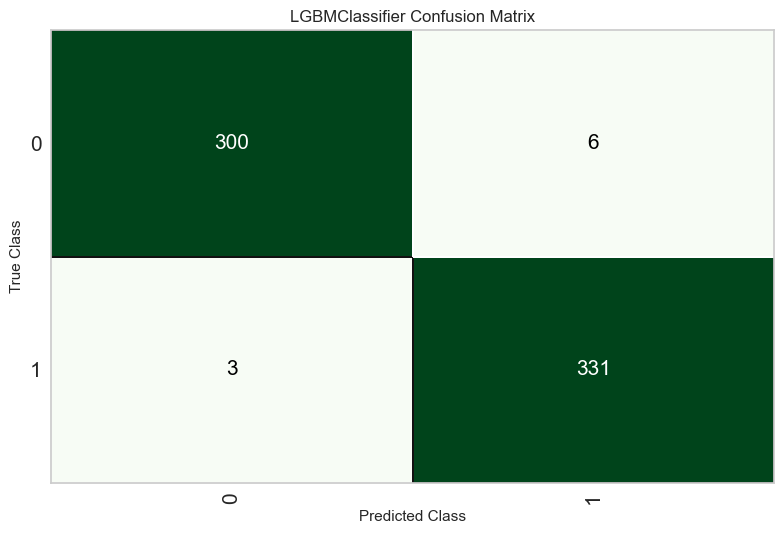

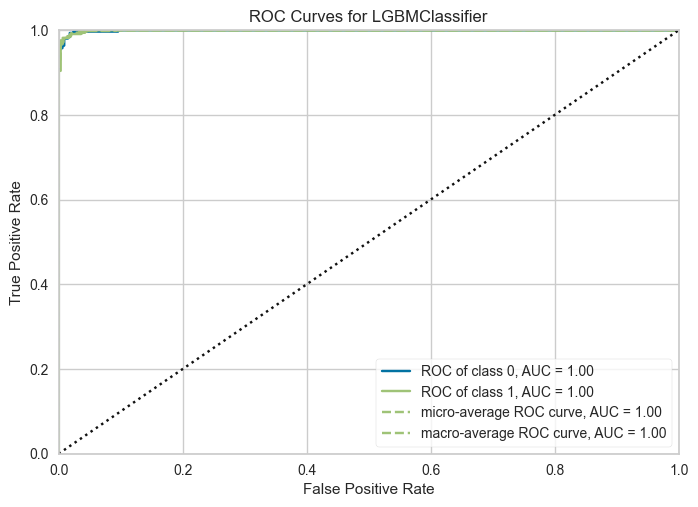

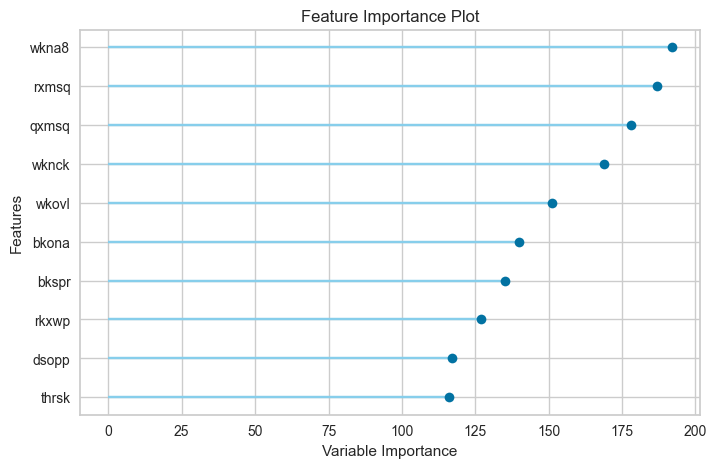

In [7]:

# Confusion matrix
plot_model(tuned_model, plot="confusion_matrix")

# ROC curve
plot_model(tuned_model, plot="auc")

# Feature importance
plot_model(tuned_model, plot="feature")


## 8. Making Predictions

I used PyCaret's `predict_model()` function to generate predictions on the held-out test dataset.

The results include the predicted class label and a prediction score indicating the model's confidence in its selected label.

The model achieved approximately 98.59% accuracy on the test data, showing that it can accurately classify chess positions that were not used during training.

In [8]:

# Predict outcomes on the held-out test set
predictions = predict_model(tuned_model)

display(predictions.head(10))


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Light Gradient Boosting Machine,0.9859,0.9992,0.9859,0.9860,0.9859,0.9718,0.9719


,bkblk,bknwy,bkon8,bkona,bkspr,bkxbq,bkxcr,bkxwp,blxwp,bxqsq,...,stlmt,thrsk,wkcti,wkna8,wknck,wkovl,wkpos,class,prediction_label,prediction_score
2556,f,f,f,f,t,f,f,f,f,t,...,f,f,f,f,t,t,n,won,won,0.9998
2557,t,f,t,f,t,f,f,f,f,t,...,f,f,f,f,f,t,n,won,won,0.9992
2558,f,f,f,f,f,t,f,f,f,f,...,f,f,t,f,t,f,n,nowin,nowin,0.9999
2559,f,f,f,f,f,f,f,f,t,f,...,f,f,f,f,t,t,n,nowin,nowin,0.9996
2560,f,f,f,t,f,t,f,f,f,f,...,f,f,f,f,t,t,n,won,won,0.9984
2561,t,f,f,f,f,f,f,f,t,t,...,f,f,f,f,t,t,n,nowin,nowin,0.9994
2562,f,f,f,f,t,f,f,f,t,f,...,f,f,f,t,t,t,t,won,won,0.9995
2563,f,f,f,t,t,t,f,f,f,f,...,f,f,f,f,t,t,n,won,won,0.9999
2564,f,f,f,f,f,f,f,t,f,f,...,f,f,f,t,t,t,t,won,won,0.9998
2565,f,f,f,f,t,f,t,t,t,t,...,f,f,f,t,t,t,n,nowin,nowin,0.9999


## 9. Finalizing and Saving the Model

After evaluating the selected model, I used PyCaret's `finalize_model()` function to retrain it using the complete dataset.

I then saved the final model using `save_model()` with the filename `Chess_Classification_Final_Model`.

This allows the trained model and its preprocessing pipeline to be loaded and reused without repeating the training process.

In [9]:

# Train the final model on the complete dataset
final_model = finalize_model(tuned_model)

# Save the trained model
save_model(final_model, "Chess_Classification_Final_Model")


Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('label_encoding',
                  TransformerWrapperWithInverse(exclude=None, include=None,
                                                transformer=LabelEncoder())),
                 ('numerical_imputer',
                  TransformerWrapper(exclude=None, include=[],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 ('...
                  LGBMClassifier(boosting_type='gbdt', class_weight=None,
                                 colsample_bytree=1.0, importance_type='split

## Conclusion

In this project, I used PyCaret to build a machine learning classification model using the Chess (King-Rook vs. King-Pawn) dataset from the UCI Machine Learning Repository.

The dataset contains 3,196 records and 35 input features. The goal was to predict whether a chess position would result in a win or no win.

I started by loading and exploring the dataset, checking for missing values, and examining the target classes. I then used PyCaret to prepare the data and compare different classification algorithms.

Light Gradient Boosting Machine (LightGBM) was selected as the best-performing model. I also performed hyperparameter tuning, but PyCaret found that the original model performed better.

The final selected model achieved approximately 98.59% accuracy on the test dataset, correctly predicting 631 out of 640 chess positions. The confusion matrix, ROC curve, and feature importance plot helped me understand the model's performance.

Overall, this project demonstrated how PyCaret can simplify the machine learning process, from data preparation and model comparison to evaluation, prediction, and saving the final trained model.